# Generating smiles for target compounds

Structures were written from the published substitutent table and verified by render against the systematic names.

Source for compounds: https://doi.org/10.2298/HEMIND181203007L

In [1]:
#imports
from pathlib import Path

import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw
from rdkit.Chem import Descriptors

In [2]:
#setting paths for the notebook

FIGURES = Path('../figures')
PROCESSED = Path('../data/processed')
FIGURES.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

In [3]:
#smiles for cores
core_1 = 'Xc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1'
core_2 = 'O=C(c1ccc(X)cc1)CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O'

In [4]:
#subsituents smiles and formulas lists per core
core_1_subs_smiles = ['','C','CO','Cl','Br','N#C','O=[N+]([O-])'] #'' gives the unsubstituted ring - H is implicit in SMILES
core_1_subs_formulas = ['H','CH3','OCH3','Cl','Br','CN','NO2']

core_2_subs_smiles = ['OC','F','Cl','Br','C#N','[N+](=O)[O-]']
core_2_subs_formulas = ['OCH3','F','Cl','Br','CN','NO2']

In [5]:
# building compounds
# 'X' in each core string marks the substitution point: index 0 in core_1,
# index 10 in core_2. Replaced positionally; the empty string in
# Structures verified downstream by molecular weight against the published table.

benzyl_series = []

for sub in core_1_subs_smiles:
    s = list(core_1)
    s[0] = sub
    benzyl_series.append(''.join(s))

phenacyl_series = []

for sub in core_2_subs_smiles:
    s = list(core_2)
    s[10] = sub
    phenacyl_series.append(''.join(s))


In [6]:
#building dataframe
compound_index_series_1 = ['1a','1b','1c','1d','1e','1f','1g']
compound_index_series_2 = ['2a','2b','2c','2d','2e','2f']

series_1 = ['benzyl']*7
series_2 = ['phenacyl']*6

columns = ['compound_id','series','substituent_formula','smiles']

s1 = pd.DataFrame(data=[compound_index_series_1,series_1,core_1_subs_formulas,benzyl_series])
s1 = s1.transpose()
s1.columns = columns
s1.set_index('compound_id', inplace=True)
s2 = pd.DataFrame(data=[compound_index_series_2,series_2,core_2_subs_formulas,phenacyl_series])
s2 = s2.transpose()
s2.columns = columns
s2.set_index('compound_id', inplace=True)



In [7]:
#merging series

df = pd.concat([s1,s2])
df

,series,substituent_formula,smiles
compound_id,,,
1a,benzyl,H,c1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
1b,benzyl,CH3,Cc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
1c,benzyl,OCH3,COc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
1d,benzyl,Cl,Clc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
1e,benzyl,Br,Brc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
1f,benzyl,CN,N#Cc1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O)cc1
1g,benzyl,NO2,O=[N+]([O-])c1ccc(CN2C(=O)C3(CCC4=CC=CC=C4C3)N...
2a,phenacyl,OCH3,O=C(c1ccc(OC)cc1)CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O
2b,phenacyl,F,O=C(c1ccc(F)cc1)CN2C(=O)C3(CCC4=CC=CC=C4C3)NC2=O


Drawing one compound from each series to confirm structure

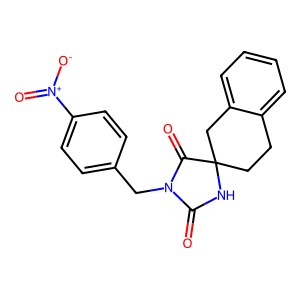

In [8]:
mol = Chem.MolFromSmiles(df['smiles']['1g'])
Draw.MolToImage(mol)

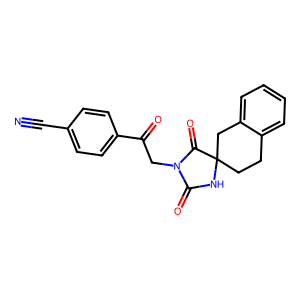

In [9]:
mol = Chem.MolFromSmiles(df['smiles']['2e'])
Draw.MolToImage(mol)

In [10]:
#Drawing grid images of two series

series_1_mol = []

for mol in s1['smiles']:
    obj = Chem.MolFromSmiles(mol)
    series_1_mol.append(obj)

img_1 = Draw.MolsToGridImage(
    mols=series_1_mol, 
    subImgSize=(800,800),
    legends=compound_index_series_1,
    returnPNG=False,
    molsPerRow=3
    )

img_1.save(FIGURES / 'benzyl_series_mols.png')

series_2_mol = []

for mol in s2['smiles']:
    obj = Chem.MolFromSmiles(mol)
    series_2_mol.append(obj)

img_2 = Draw.MolsToGridImage(
    mols=series_2_mol, 
    subImgSize=(800,800),
    legends=compound_index_series_2,
    returnPNG=False,
    molsPerRow=3
    )

img_2.save(FIGURES / 'phenacyl_series_mols.png')

In [11]:
#checking molecular weights to additionally confirm structure

mw_of_mols = []

for mol in df['smiles']:
    obj = Chem.MolFromSmiles(mol)
    mw_of_mols.append(Descriptors.MolWt(obj))

id = compound_index_series_1 + compound_index_series_2

checking_table = pd.DataFrame(data=[id,mw_of_mols]).transpose()
columns = ['series','molecular_weight']
checking_table.columns =columns

checking_table

,series,molecular_weight
0,1a,306.365
1,1b,320.392
2,1c,336.391
3,1d,340.81
4,1e,385.261
5,1f,331.375
6,1g,351.362
7,2a,364.401
8,2b,352.365
9,2c,368.82


Molecular weights match values reported in the paper. The dataframe is ready for the next stage.

In [12]:
#Exporting dataframe

df.to_csv(PROCESSED / 'targets_df.csv')